# سامانهٔ اولویت‌بندی تماس با مشتریان Olist

تیم پشتیبانی برای هر دسته از سفارش‌های تازه‌تأییدشده ظرفیت محدودی دارد. این دفترچه نتیجهٔ اجرای خط لوله، روش انتخاب مدل و عملکرد صف تماس را در دادهٔ آزمون عمومی نشان می‌دهد. برای اجرای دوباره ابتدا مراحل README را انجام دهید.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

plt.style.use("seaborn-v0_8-darkgrid")
root = Path("part4") if Path("part4/capstone").is_dir() else Path(".")
out = root / "artifacts"

def read_result(name):
    return json.loads((out / name).read_text(encoding="utf-8"))

if not (out / "evaluation.json").is_file():
    raw_dir = os.environ.get("FTI_CAPSTONE_RAW_DIR")
    if not raw_dir:
        raise FileNotFoundError("Build the artifacts or configure the notebook build as described in the README.")
    from capstone.runner import main

    main(["build", "--raw-dir", raw_dir, "--output", str(out)])
results = read_result("evaluation.json")
winner = results["model_selected"]
metrics = results["metrics"]


## ساخت و بررسی داده‌ها

تعداد ردیف‌های پذیرفته و قرنطینه‌شده و زمان اجرای هر مرحله را می‌بینیم. زمان کوئری از گزارش اجرای PostgreSQL برای همهٔ سفارش‌های واجد شرایط گرفته شده است.

In [2]:
display(pd.Series(read_result("timings.json"), name="Seconds").round(2).to_frame())
print(f"Full feature query: {read_result('feature_query_plan.json')[0]['Execution Time']:.1f} ms")
print(f"Missing approvals excluded: {results['approved_timestamp_missing_excluded']:,}")
if (out / "ingestion_manifest.json").is_file():
    display(pd.DataFrame(read_result("ingestion_manifest.json")["datasets"]).T)

,Seconds
migrations_seconds,0.06
load_seconds,52.97
feature_seconds,1.04
training_seconds,83.31
total_seconds,137.43


Full feature query: 291.0 ms
Missing approvals excluded: 160


,source,loaded,quarantined
category_translations,71,71,0
customers,99441,99441,0
sellers,3095,3095,0
products,32951,32938,13
orders,99441,99441,0
order_items,112650,112626,24
order_payments,103886,103886,0
order_reviews,99224,99224,0
geolocation,1000163,1000163,0


## انتخاب مدل پیش از آزمون

در هر ماه اعتبارسنجی، فقط نظرهایی برای آموزش استفاده می‌شوند که پیش از آغاز همان ماه دریافت شده‌اند. سفارش‌های بدون نظر قطعی نیز ظرفیت تماس را مصرف می‌کنند. مدل بر اساس پوشش مجموع نظرهای منفی شناخته‌شده در این ماه‌ها انتخاب می‌شود.

In [3]:
folds = results["validation_folds"]
validation = pd.DataFrame({
    month: {name: row["recall"] for name, row in fold["models"].items()}
    for month, fold in folds.items()
}).T
validation.loc["Pooled recall"] = results["validation_recall_10pct"]
display(validation.style.format("{:.2%}"))
print(f"Selected family: {winner} | Holdout starts: {results['cutoff_month']}")

,logistic,random_forest
2018-02,7.54%,5.56%
2018-03,11.71%,12.64%
2018-04,6.15%,5.90%
Pooled recall,8.98%,8.90%


Selected family: logistic | Holdout starts: 2018-05


## عملکرد در ظرفیت‌های مختلف تماس

مدل منتخب را روی دورهٔ آزمون زمانی با قاعدهٔ سادهٔ تأخیر تأیید مقایسه می‌کنیم. ستون تعداد تماس با نظر ثبت‌شده، مخرج معیار دقت در سفارش‌های دارای نظر است.

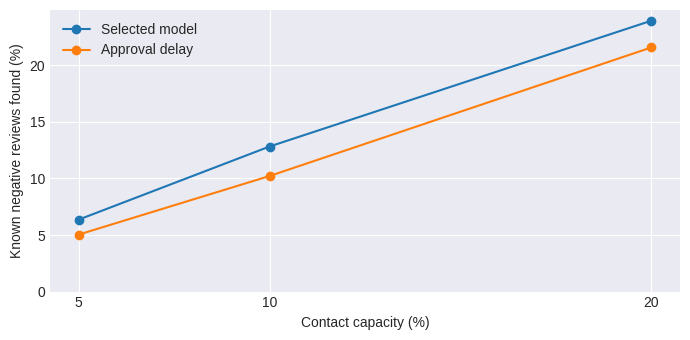

,total_flagged,flagged_with_review,precision,recall,confusion_matrix_tn_fp_fn_tp
0.05,1301,1293,0.141531,0.063586,"[21904, 1110, 2695, 183]"
0.1,2602,2581,0.142968,0.128214,"[20802, 2212, 2509, 369]"
0.2,5205,5169,0.133295,0.239402,"[18534, 4480, 2189, 689]"


,Latest month
eligible_orders,1
total_flagged,0
n,1
positives,1
selected,0
precision,None
recall,0.0
f1,0.0
roc_auc,None
confusion_matrix_tn_fp_fn_tp,"[0, 0, 1, 0]"


In [4]:
comparison = pd.DataFrame({
    "Selected model": {float(capacity) * 100: row["recall"] for capacity, row in metrics[winner].items()},
    "Approval delay": {
        float(capacity) * 100: row["recall"]
        for capacity, row in metrics["approval_delay_baseline"].items()
    },
}).sort_index()
ax = (100 * comparison).plot(marker="o", figsize=(7, 3.5), xticks=comparison.index)
ax.set(xlabel="Contact capacity (%)", ylabel="Known negative reviews found (%)", ylim=(0, None))
plt.tight_layout()
plt.show()
table = pd.DataFrame.from_dict(metrics[winner], orient="index")
display(table[["total_flagged", "selected", "precision", "recall", "confusion_matrix_tn_fp_fn_tp"]].rename(
    columns={"selected": "flagged_with_review"}
))
display(pd.Series(results["last_month"], name="Latest month").to_frame())

## بازپخش سفارش‌های آزمون و استفاده از صف

بازپخش کامل، فایل خام سفارش‌ها را بدون اطلاعات تحویل به دستور پیش‌بینی می‌دهد و زمان تأیید، رتبه‌بندی، امتیاز و علامت تماس را با خروجی ارزیابی مقایسه می‌کند. نتیجهٔ این کنترل و خلاصهٔ عملیاتی در ادامه آمده‌اند.

In [5]:
if (out / "replay.json").is_file():
    display(pd.Series(read_result("replay.json"), name="Replay evidence").to_frame())
ranked = pd.read_csv(out / "follow_up_ranked.csv", usecols=["risk_score", "follow_up"])
print(f"Ranked: {len(ranked):,} | Flagged: {ranked.follow_up.sum():,}")
display(Markdown((out / "operations_summary.md").read_text(encoding="utf-8")))

,Replay evidence
orders_matched,26027.0
orders_flagged,2602.0
max_absolute_score_difference,0.0
feature_query_budget_ms,500.0
build_budget_seconds,2700.0


Ranked: 26,027 | Flagged: 2,602


# Customer support follow-up

Start at the top of the ranked list and contact the flagged customers. Use the list to offer order updates and log whether customers needed help.

The public holdout contained 26,027 eligible orders and 25,892 had reviews. Orders without reviews still count toward the contact limit.

| Contact limit | Flagged | Flagged with reviews | Known negative reviews found | Precision among reviewed alerts |
|---|---:|---:|---:|---:|
| 5% | 1,301 | 1,293 | 6.4% | 14.2% |
| 10% | 2,602 | 2,581 | 12.8% | 14.3% |
| 20% | 5,205 | 5,169 | 23.9% | 13.3% |

In 2018-09, the 10% limit allowed 0 contacts. Eligible orders totaled 1. Of those, 1 had reviews and 1 had negative reviews. The list found 0.0% of those orders.

Compare a small, randomly assigned outreach group with usual service to measure whether contacting customers helps.
